<div style="border-left:6px solid #b30338; padding:8px 16px;">

# MCDI505 — Análisis de Series de Tiempo
## Sumativa 1 · Informe de análisis exploratorio de series de tiempo
### Consumo eléctrico mensual del segmento comercial — Distribuidora Eléctrica del Litoral (DEL)

**Autor:** Roberto Moncada  
**Programa:** Magíster en Ciencia de Datos · UNAB Online  
**Curso:** MCDI505 — Análisis de Series de Tiempo · Unidad 1, Semana 1  
**Archivo:** `mcdi505_s1rmoncada.ipynb` · **Fecha:** septiembre de 2026

</div>

**Resumen.** 
Este informe estudia el consumo eléctrico comercial de DEL entre 2015 y 2023 y describe sus principales comportamientos. Primero, se observa que el consumo fue creciendo hasta aproximadamente 2018 y luego comenzó a estabilizarse. También existe una estacionalidad anual muy marcada, es decir, hay ciertos patrones de consumo que se repiten año tras año. Esto queda reflejado en una fuerza estacional de Fs = 0,90, donde enero presenta los consumos más altos y mayo los más bajos.

Uno de los cambios más importantes de la serie ocurre durante el periodo del COVID-19, cuando el consumo disminuye considerablemente. Entre marzo de 2020 y diciembre de 2021 se estiman aproximadamente 195 GWh que no fueron consumidos. También se encontró un dato fuera de lo habitual en noviembre de 2017 y la incorporación de unos 900 clientes en abril de 2019, que no produjo un cambio visible en el consumo (sección 3.5).

Por otro lado, al revisar la función de autocorrelación se observa que la serie mantiene relación con sus valores anteriores. La ACF disminuye lentamente y aparecen picos cada 12 meses, específicamente en los rezagos 12, 24, 36 y 48. Esto permite concluir que la serie no es estacionaria en su estado original y que tiene una fuerte componente estacional.

Por lo tanto, antes de construir el modelo sería necesario preparar la serie. Para el modelamiento se propone evaluar una transformación logarítmica frente a Box-Cox, aplicar una diferenciación estacional y verificar con ADF y KPSS si además se necesita una regular. También se considera importante tratar el periodo del COVID-19 de forma separada, porque representa un comportamiento extraordinario que podría influir en los resultados del modelo.

**Palabras clave:** series de tiempo, estacionalidad, descomposición, ACF, PACF, consumo eléctrico.

**Organización.** El informe sigue el orden de los criterios de evaluación: (1) contexto, (2) preparación de datos, (3) exploración, (4) descomposición, (5) autocorrelación, (6) interpretación integrada, (7) conclusiones y (8) referencias. Cada decisión metodológica se presenta con cuatro partes: qué se decidió, la evidencia, la alternativa descartada y las consecuencias.

**Conceptos clave.** 
**Ciclo:** fluctuaciones de largo plazo en la serie que no siguen un patrón fijo ni se repiten en intervalos regulares. Representan periodos de crecimiento o caída que pueden durar varios años.

**Estacionariedad:** propiedad de una serie en la que su comportamiento general se mantiene estable en el tiempo. Esto significa que la media y la variabilidad no cambian significativamente a lo largo del periodo analizado.


# 1. Introducción y contexto del dataset

**La Distribuidora Eléctrica del Litoral (DEL)** necesita estimar el consumo de su segmento comercial para planificar la energía a contratar y reducir posibles costos. Esta primera etapa busca analizar el comportamiento histórico de la serie antes de realizar un pronóstico.

La pregunta de negocio es cuánto consumo mensual se espera para los próximos doce meses, con qué incertidumbre y qué volumen contratar. Este informe busca entender cómo está construida la serie (tendencia, estacionalidad, ciclo y error) y relacionarla con la ACF y la PACF. 

**Datos.** El archivo consumo_electrico_litoral.csv contiene 120 registros mensuales (2015-2024) y cuatro variables: consumo eléctrico (consumo_gwh), clientes comerciales, temperatura media y días hábiles. El consumo en GWh es la variable principal. Los datos son sintéticos y representan la estructura de una serie real (Universidad Andrés Bello, s. f.). El periodo estacional es s=12.

**Partición.** Se analizan 108 observaciones de 2015 a 2023, mientras que 2024 se reserva como conjunto de prueba, evitando utilizar información futura en el análisis (Tashman, 2000).

**Hechos del periodo.** Se consideran tres eventos relevantes: un dato anómalo por una recalibración de medidores en noviembre de 2017, el ingreso de aproximadamente 900 clientes en abril de 2019 y las restricciones por COVID-19 entre marzo de 2020 y diciembre de 2021.
  


# 2. Configuración y preparación de los datos

Se fija una semilla aleatoria, se usan rutas relativas y no se modifica el archivo original, de modo que el notebook sea reproducible. Luego se verifica la integridad de la serie. Se usan `pandas`, `matplotlib` y `statsmodels` (Seabold y Perktold, 2010); el código está comentado.

In [1]:
# ============================================================
# 2.1 Librerías y configuración general
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
np.random.seed(505)                      # semilla fija (reproducibilidad)

# Paleta sobria y consistente en todo el informe
ROJO, AZUL, VERDE, GRIS, NEGRO = "#b30338", "#0057b8", "#2e7d32", "#9e9e9e", "#222222"
plt.rcParams.update({
    "figure.figsize": (11, 3.8), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9,
})

# Hitos del caso (contexto entregado en el documento base del curso)
COVID_INI, COVID_FIN = pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01")
CLIENTES = pd.Timestamp("2019-04-01")   # incorporación de ~900 clientes comerciales
MEDIDORES = pd.Timestamp("2017-11-01")  # recalibración de medidores (atípico)
print("pandas", pd.__version__, "· numpy", np.__version__)

pandas 3.0.6 · numpy 2.5.3


In [2]:
# ============================================================
# 2.2 Carga de datos (ruta relativa) y SELLADO del conjunto de prueba
# ============================================================
ARCHIVO = "consumo_electrico_litoral.csv"
ruta = next(p for p in [Path(ARCHIVO), Path("datos") / ARCHIVO, Path("..") / "datos" / ARCHIVO]
            if p.exists())

# asfreq("MS") fuerza el calendario mensual: un mes ausente quedaría como NaN
df_total = pd.read_csv(ruta, parse_dates=["fecha"]).set_index("fecha").asfreq("MS")

# Partición cronológica: 2015-01 a 2023-12 (entrenamiento) | 2024 (prueba sellada).
# A partir de esta línea NO se vuelve a usar el año 2024 en ningún cálculo ni gráfico.
CORTE = "2023-12-31"
df = df_total.loc[:CORTE].copy()
del df_total

print(f"Archivo: {ruta}")
print(f"Periodo analizado: {df.index.min():%Y-%m} a {df.index.max():%Y-%m} "
      f"({len(df)} observaciones = {len(df)//12} años completos)")
display(df.head())

Archivo: consumo_electrico_litoral.csv
Periodo analizado: 2015-01 a 2023-12 (108 observaciones = 9 años completos)


,consumo_gwh,clientes_comerciales,temperatura_media_c,dias_habiles
fecha,,,,
2015-01-01,108.32,41827,19.6,22
2015-02-01,94.71,41918,18.7,20
2015-03-01,89.52,42045,16.5,22
2015-04-01,82.24,42129,13.3,22
2015-05-01,82.60,42242,12.0,21


In [3]:
# ============================================================
# 2.3 Ficha técnica y auditoría de integridad
# ============================================================
print("Frecuencia del índice :", df.index.freqstr)
print("Índice ordenado       :", df.index.is_monotonic_increasing)
print("Índice sin duplicados :", df.index.is_unique)
completo = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("Calendario completo   :", df.index.equals(completo))
print("Consumo <= 0          :", int((df["consumo_gwh"] <= 0).sum()))
print("Nulos en consumo      :", df["consumo_gwh"].isna().sum(),
      list(df.index[df["consumo_gwh"].isna()].strftime("%Y-%m")))


display(df.describe().T.round(2))

Frecuencia del índice : MS
Índice ordenado       : True
Índice sin duplicados : True
Calendario completo   : True
Consumo <= 0          : 0
Nulos en consumo      : 3 ['2016-08', '2019-02', '2022-06']


,count,mean,std,min,25%,50%,75%,max
consumo_gwh,105.0,102.85,12.67,73.19,94.71,101.31,111.08,133.58
clientes_comerciales,108.0,48634.68,4191.69,41827.00,44891.75,48952.50,52340.75,55436.00
temperatura_media_c,108.0,15.59,3.20,10.50,12.50,15.30,18.40,21.70
dias_habiles,108.0,21.73,0.94,20.00,21.00,22.00,22.00,23.00


 
**Lectura de la auditoría.** 
Se observa que el índice está ordenado correctamente por mes y coincide con el calendario mensual completo y no existen registros duplicados. Tampoco se encontraron consumos iguales o menores a cero. Sin embargo, faltan tres datos correspondientes a agosto de 2016, febrero de 2019 y junio de 2022, un 2,8 % de las 108 observaciones, atribuidos a fallas de telemetría. En general, el consumo promedio es de 102,85 GWh, con valores que van desde 73,19 hasta 133,58 GWh.

In [4]:
# ============================================================
# 2.4 Valores faltantes: comparación de estrategias y decisión
# ============================================================
s = df["consumo_gwh"]
huecos = s[s.isna()].index

estrategias = {
    "lineal": s.interpolate("linear"),
    "temporal": s.interpolate("time"),
    # mismo mes del año previo, escalado por la razón entre el mes anterior y su par del año previo
    "estacional": s.fillna(s.shift(12) * (s.shift(1) / s.shift(13))),
}
comp = pd.DataFrame({k: v.loc[huecos] for k, v in estrategias.items()}).round(2)
comp.insert(0, "mes", huecos.month)
comp["máx-mín"] = (comp[["lineal", "temporal", "estacional"]].max(axis=1)
                   - comp[["lineal", "temporal", "estacional"]].min(axis=1)).round(2)
display(comp)

# Decisión: interpolación temporal para los tres huecos (ver justificación en el texto)
y = s.interpolate("time")
y.name = "consumo_gwh"

# Impacto de la decisión sobre media, desviación estándar y autocorrelación de orden 1
impacto = pd.DataFrame({
    k: {"media": v.mean(), "desv. estándar": v.std(), "ACF(1)": v.autocorr(1)}
    for k, v in {"lineal": estrategias["lineal"], "temporal": estrategias["temporal"]}.items()
}).T
display(impacto.round(4))

,mes,lineal,temporal,estacional,máx-mín
fecha,,,,,
2016-08-01,8,95.86,95.86,94.87,0.99
2019-02-01,2,116.93,116.34,114.18,2.75
2022-06-01,6,101.40,101.43,103.86,2.46


,media,desv. estándar,ACF(1)
lineal,102.9001,12.5828,0.7672
temporal,102.8950,12.5768,0.7670


### Decisión 1 — Valores faltantes
| Elemento | Detalle |
|---|---|
| **Qué se decidió** | Se completaron los tres datos faltantes usando interpolación temporal, tomando como referencia los valores cercanos de cada mes.|
| **Evidencia** | Los datos faltantes aparecen en distintos meses y, al comparar las alternativas, las diferencias fueron pequeñas: difieren solo 0,99, 2,75 y 2,46 GWh (a lo más 2,4 % del nivel). Además, los meses vecinos cuentan con datos reales.|
| **Alternativa descartada** | No se utilizó la imputación estacional porque depende del valor del mismo mes del año anterior, lo que podría incorporar variaciones excepcionales, como las relacionadas con el periodo COVID.|
| **Consecuencia** | La interpolación tuvo un impacto mínimo en los resultados generales. De todas formas, se considera que 3 de los 108 datos fueron estimados y no corresponden a valores observados directamente.|


# 3. Exploración y visualización de la serie

## 3.1 Serie completa

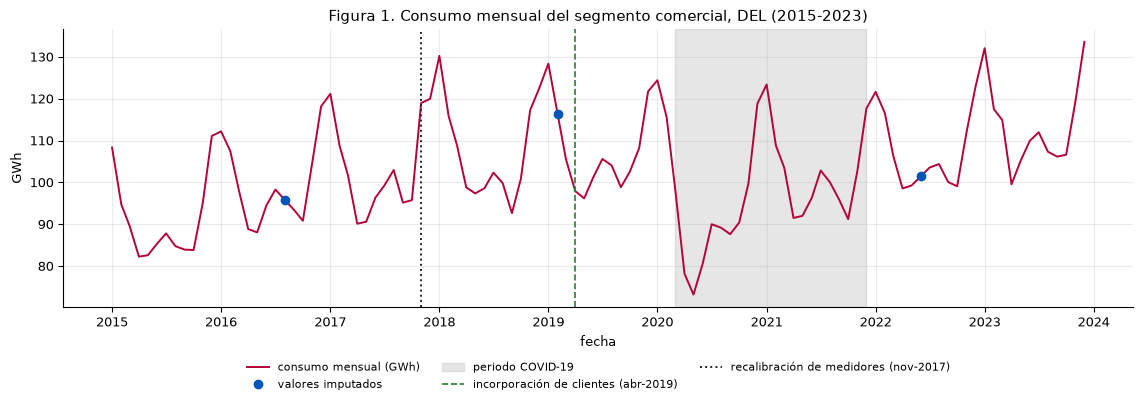

In [5]:
# ============================================================
# 3.1 Serie completa con hitos y valores imputados
# ============================================================
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.plot(y.index, y.values, color=ROJO, lw=1.4, label="consumo mensual (GWh)")
ax.plot(huecos, y.loc[huecos], "o", color=AZUL, ms=6, zorder=5, label="valores imputados")
ax.axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25, label="periodo COVID-19")
ax.axvline(CLIENTES, color=VERDE, ls="--", lw=1.2, label="incorporación de clientes (abr-2019)")
ax.axvline(MEDIDORES, color=NEGRO, ls=":", lw=1.4, label="recalibración de medidores (nov-2017)")
ax.set_ylabel("GWh"); ax.set_xlabel("fecha")
ax.set_title("Figura 1. Consumo mensual del segmento comercial, DEL (2015-2023)")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False)
plt.tight_layout(); plt.show()

**Descripción (Figura 1).** La serie presenta un comportamiento estacional que se repite cada año, con mayores consumos en verano, menores niveles en otoño y un aumento más suave en invierno. Dentro de este comportamiento se destacan cuatro puntos:

- **2015-2018:** existe una tendencia al alza, con un aumento de la media anual desde 90,8 hasta 107,1 GWh.

- **2018-2019:** el consumo se mantiene prácticamente estable en 107,1 y 107,2 GWh.

- **Desde marzo de 2020:** se produce una fuerte caída, llegando a 73,2 GWh en mayo de 2020. El consumo comienza a recuperarse en 2021 y se normaliza durante 2022. En 2020 la media fue de 95,5 GWh, un 11 % menor que en 2019.

- **Noviembre de 2017:** se observa un valor máximo aislado, que será revisado en la sección siguiente.

En general, la variación de la serie es estable, excepto durante el periodo COVID, donde los cambios son más marcados. Además, no se observa un cambio importante en abril de 2019, como se revisa en la sección 3.5.


## 3.2 Variación interanual y dato atípico de noviembre de 2017

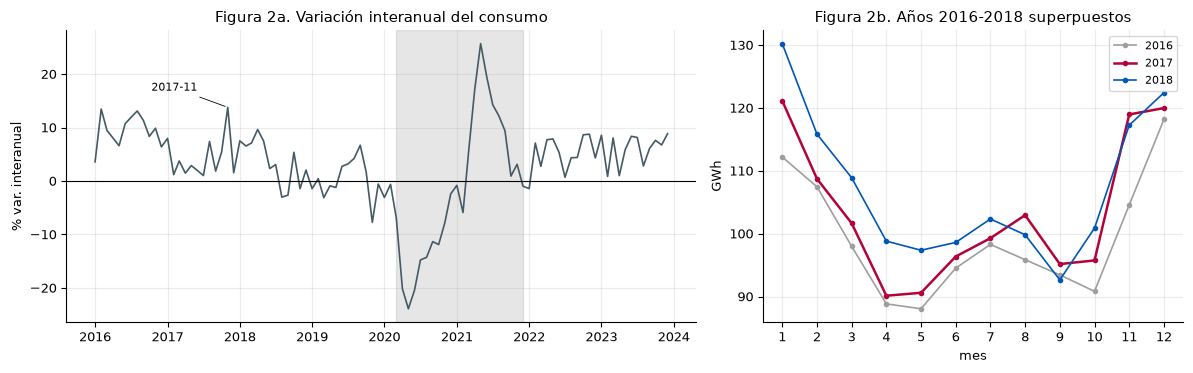

Candidatos a atípico (|z robusto| > 3,5):
fecha
2017-11-01    4.10
2019-10-01    3.56
2020-02-01    3.81
2020-04-01   -5.27
2020-05-01   -7.56
2020-06-01   -5.27

Noviembre de 2017: 118.96 GWh | octubre: 95.74 | diciembre: 119.97 | nov-2016: 104.56 | nov-2018: 117.25
Valor esperado para nov-2017: 109.86 GWh (exceso observado: +9.10 GWh)
Efecto de ajustarlo -> media: 102.895 vs 102.811 | desv. estándar: 12.577 vs 12.498
Variación interanual de nov-2017: +13.8%  |  de nov-2018: -1.4%


In [6]:
# ============================================================
# 3.2 Variación interanual y aislamiento del atípico de 2017-11
# ============================================================
yoy = (y / y.shift(12) - 1) * 100          # % respecto del mismo mes del año anterior

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].plot(yoy.index, yoy.values, color="#455a64", lw=1.2)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0].annotate("2017-11", (MEDIDORES, yoy.loc[MEDIDORES]), xytext=(-55, 12),
                 textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.6))
axes[0].set_ylabel("% var. interanual")
axes[0].set_title("Figura 2a. Variación interanual del consumo")

# 2016, 2017 y 2018 superpuestos para aislar el dato de noviembre de 2017
for anio, col, lw in [(2016, GRIS, 1.2), (2017, ROJO, 1.8), (2018, AZUL, 1.2)]:
    g = y[str(anio)]
    axes[1].plot(g.index.month, g.values, color=col, lw=lw, marker="o", ms=3, label=str(anio))
axes[1].set_xticks(range(1, 13)); axes[1].set_xlabel("mes"); axes[1].set_ylabel("GWh")
axes[1].set_title("Figura 2b. Años 2016-2018 superpuestos"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# z robusto del componente irregular (mismo procedimiento que la auditoría del curso):
# 1) nivel = media móvil centrada 2x12; 2) razón serie/nivel; 3) dividir por la mediana del mes
nivel = y.rolling(12, center=True).mean().rolling(2, center=True).mean().shift(-1)
razon = (y / nivel).dropna()
irregular = razon / razon.groupby(razon.index.month).transform("median")
mad = (irregular - irregular.median()).abs().median()
z = (irregular - irregular.median()) / (1.4826 * mad)
candidatos = z[z.abs() > 3.5].round(2)
print("Candidatos a atípico (|z robusto| > 3,5):")
print(candidatos.rename("z").to_string())
print(f"\nNoviembre de 2017: {y.loc[MEDIDORES]:.2f} GWh | octubre: {y.loc['2017-10-01']:.2f} | "
      f"diciembre: {y.loc['2017-12-01']:.2f} | nov-2016: {y.loc['2016-11-01']:.2f} | nov-2018: {y.loc['2018-11-01']:.2f}")

# Efecto de reemplazar el dato por su valor esperado (nivel x razón mediana de noviembre)
esperado = nivel.loc[MEDIDORES] * razon.groupby(razon.index.month).median().loc[11]
y_aj = y.copy(); y_aj.loc[MEDIDORES] = esperado
print(f"Valor esperado para nov-2017: {esperado:.2f} GWh (exceso observado: {y.loc[MEDIDORES] - esperado:+.2f} GWh)")
print(f"Efecto de ajustarlo -> media: {y.mean():.3f} vs {y_aj.mean():.3f} | desv. estándar: {y.std():.3f} vs {y_aj.std():.3f}")
print(f"Variación interanual de nov-2017: {yoy.loc[MEDIDORES]:+.1f}%  |  de nov-2018: {yoy.loc['2018-11-01']:+.1f}%")

**Descripción (Figuras 2a y 2b).** Entre 2016 y 2019 la variación interanual promedia +4,4 % (de −7,7 % a +13,8 %): crecimiento moderado hasta 2018 y desaceleración después. Noviembre de 2017 presenta un comportamiento atípico, con un aumento de +24 % respecto a octubre y un z robusto de +4,10. En 2020 destaca la caída asociada al COVID (−23,9 % en mayo) y el aumento de 2021 responde principalmente a un efecto base.

### Decisión 2 — Atípico de noviembre de 2017

| Elemento | Detalle |
|---|---|
| **Qué se decidió** | **Conservar** el dato en esta etapa exploratoria, **marcarlo** y reemplazarlo por su valor esperado antes de modelar. |
| **Evidencia** | El valor presenta un exceso de +9,10 GWh respecto de lo esperado (109,86 GWh), equivalente a un 8,3 %. Se relaciona con una recalibración de medidores y no con un aumento real del consumo. Al corregirlo, la media cambia de 102,895 a 102,811 GWh y la desviación estándar de 12,577 a 12,498 GWh.|
| **Alternativa descartada** | Eliminarlo sin registro rompería el índice mensual y la trazabilidad; dejarlo sin marcar metería ruido falso en la ACF y en la estimación. |
| **Consecuencia** | El dato aparece como uno de los mayores residuos positivos (+7,0 %). Para el modelamiento se puede tratar como un valor faltante mediante interpolación o incorporar una variable indicadora. |


## 3.3 Patrón estacional y su relación con la temperatura

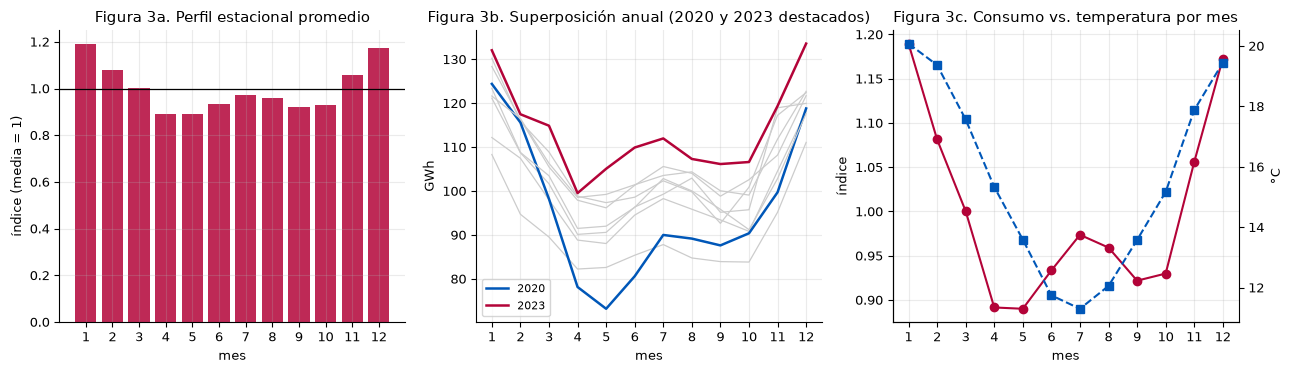

Índice estacional por mes: {1: 1.19, 2: 1.081, 3: 1.0, 4: 0.892, 5: 0.89, 6: 0.933, 7: 0.974, 8: 0.959, 9: 0.922, 10: 0.93, 11: 1.056, 12: 1.173}
Temperatura media por mes: {1: 20.1, 2: 19.4, 3: 17.6, 4: 15.3, 5: 13.6, 6: 11.7, 7: 11.3, 8: 12.1, 9: 13.6, 10: 15.2, 11: 17.9, 12: 19.4}
Correlación mensual perfil-temperatura: +0.80


In [7]:
# ============================================================
# 3.3 Patrón estacional: perfil promedio, superposición anual y temperatura
# ============================================================
perfil = y.groupby(y.index.month).mean() / y.mean()          # índice estacional simple
temp_mes = df["temperatura_media_c"].groupby(df.index.month).mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].bar(perfil.index, perfil.values, color=ROJO, alpha=0.85)
axes[0].axhline(1, color="k", lw=0.9)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("mes"); axes[0].set_ylabel("índice (media = 1)")
axes[0].set_title("Figura 3a. Perfil estacional promedio")

for anio, g in y.groupby(y.index.year):
    especial = anio in (2020, 2023)
    axes[1].plot(g.index.month, g.values, lw=1.8 if especial else 0.9,
                 color={2020: AZUL, 2023: ROJO}.get(anio, "#cccccc"),
                 label=str(anio) if especial else None)
axes[1].set_xticks(range(1, 13)); axes[1].set_xlabel("mes"); axes[1].set_ylabel("GWh")
axes[1].set_title("Figura 3b. Superposición anual (2020 y 2023 destacados)")
axes[1].legend(fontsize=8)

axes[2].plot(perfil.index, perfil.values, "o-", color=ROJO, label="índice estacional del consumo")
ax2 = axes[2].twinx()
ax2.plot(temp_mes.index, temp_mes.values, "s--", color=AZUL, label="temperatura media (°C)")
ax2.grid(False); ax2.spines["right"].set_visible(True)
axes[2].set_xticks(range(1, 13)); axes[2].set_xlabel("mes")
axes[2].set_ylabel("índice"); ax2.set_ylabel("°C")
axes[2].set_title("Figura 3c. Consumo vs. temperatura por mes")
plt.tight_layout(); plt.show()

print("Índice estacional por mes:", dict(zip(perfil.index, perfil.round(3))))
print("Temperatura media por mes:", dict(zip(temp_mes.index, temp_mes.round(1))))
print("Correlación mensual perfil-temperatura: "
      f"{np.corrcoef(perfil.values, temp_mes.values)[0, 1]:+.2f}")

**Descripción (Figuras 3a-3c).** Se observa una estacionalidad marcada, con mayor consumo en enero (1,19), menor en abril-mayo (0,89) y un repunte en **julio** (0,97) sobre junio (0,93) y agosto (0,96). El patrón se mantiene entre los años, excepto en 2020.

**Doble estacionalidad.** El consumo aumenta tanto con frío como con calor. Por tramos de temperatura, el consumo medio es de 97,1 GWh con 12 °C o menos, de 95,0 y 95,3 GWh entre 12 y 16 °C, de 100,1 GWh entre 16 y 18 °C y de 116,8 GWh sobre 18 °C. Esto forma una U asimétrica, donde el frío eleva el consumo un 2 % sobre el mínimo y el calor un 23 %. Por eso domina el máximo de verano.

## 3.4 Estabilidad de la media y de la varianza

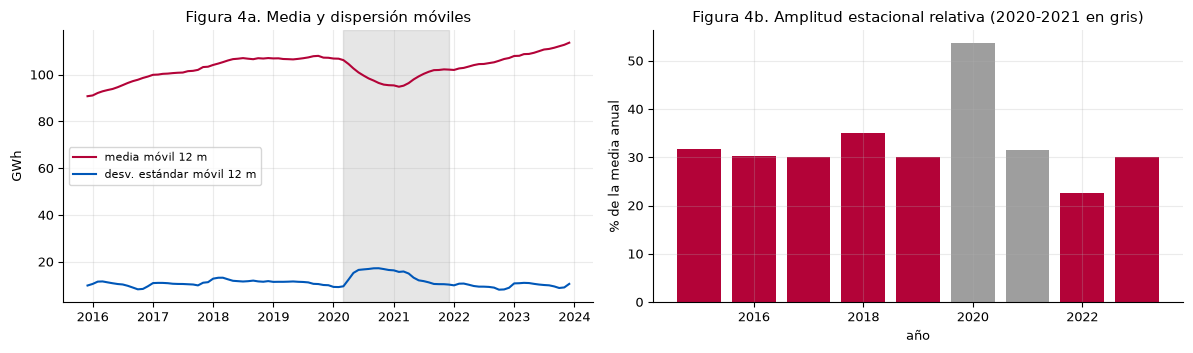

,media anual (GWh),amplitud pico-valle (GWh),amplitud relativa (%),CV intra-anual
año,,,,
2015,90.78,28.84,31.77,0.11
2016,99.18,30.11,30.36,0.10
2017,103.39,31.01,29.99,0.11
2018,107.09,37.59,35.10,0.11
2019,107.21,32.18,30.02,0.09
2020,95.49,51.21,53.63,0.17
2021,102.15,32.19,31.51,0.10
2022,107.11,24.16,22.56,0.08
2023,113.66,34.05,29.96,0.09


Excluyendo 2020-2021: amplitud absoluta 28.8 -> 34.1 GWh; relativa 31.8% -> 30.0% (desv. estándar de la relativa: 3.76 pp)
Elasticidad de la desv. estándar anual respecto de la media anual: 0.31
Correlación media móvil-desv. móvil antes de COVID (2015-2019): +0.43


In [8]:
# ============================================================
# 3.4 Nivel y dispersión: media/desv. móviles y amplitud estacional por año
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
rm, rs = y.rolling(12).mean(), y.rolling(12).std()
axes[0].plot(rm, color=ROJO, label="media móvil 12 m")
axes[0].plot(rs, color=AZUL, label="desv. estándar móvil 12 m")
axes[0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0].set_ylabel("GWh"); axes[0].legend(fontsize=8)
axes[0].set_title("Figura 4a. Media y dispersión móviles")

amp = pd.DataFrame({"media anual (GWh)": y.groupby(y.index.year).mean(),
                    "amplitud pico-valle (GWh)": y.groupby(y.index.year).max() - y.groupby(y.index.year).min()})
amp["amplitud relativa (%)"] = 100 * amp.iloc[:, 1] / amp.iloc[:, 0]
amp["CV intra-anual"] = y.groupby(y.index.year).std() / y.groupby(y.index.year).mean()
amp.index.name = "año"
axes[1].bar(amp.index, amp["amplitud relativa (%)"], color=[GRIS if a in (2020, 2021) else ROJO for a in amp.index])
axes[1].set_ylabel("% de la media anual"); axes[1].set_xlabel("año")
axes[1].set_title("Figura 4b. Amplitud estacional relativa (2020-2021 en gris)")
plt.tight_layout(); plt.show()
display(amp.round(2))

normales = amp.drop(index=[2020, 2021])
print("Excluyendo 2020-2021: amplitud absoluta "
      f"{normales.iloc[0, 1]:.1f} -> {normales.iloc[-1, 1]:.1f} GWh; relativa "
      f"{normales.iloc[0, 2]:.1f}% -> {normales.iloc[-1, 2]:.1f}% "
      f"(desv. estándar de la relativa: {normales.iloc[:, 2].std():.2f} pp)")
# Elasticidad de la dispersión respecto del nivel (años sin COVID): 0 = aditivo puro, 1 = multiplicativo puro
lm = np.log(y.groupby(y.index.year).mean().drop(index=[2020, 2021]))
ls = np.log(y.groupby(y.index.year).std().drop(index=[2020, 2021]))
print(f"Elasticidad de la desv. estándar anual respecto de la media anual: {np.polyfit(lm, ls, 1)[0]:.2f}")
print("Correlación media móvil-desv. móvil antes de COVID (2015-2019): "
      f"{np.corrcoef(rm[:'2019-12'].dropna(), rs[:'2019-12'].dropna())[0, 1]:+.2f}")

**Descripción (Figuras 4a y 4b).** La media móvil aumenta de 90,8 GWh en 2015 a cerca de 107 GWh en 2018-2019, cae durante el COVID y se recupera a 113,7 GWh en 2023, mostrando que la serie no es estacionaria en media. La desviación móvil se mantiene entre 8 y 13 GWh fuera del shock y no sigue claramente al nivel (correlación +0,43 antes del COVID). La amplitud estacional relativa se mantiene cercana al 30 %, mientras la absoluta aumenta de 28,8 a 34,1 GWh. En 2020 ambos indicadores aumentan (la amplitud relativa llega a 53,6 %) por el efecto del COVID.

**Lectura.** Los resultados muestran una tendencia hacia un esquema multiplicativo, porque la amplitud relativa es estable y la absoluta crece con el nivel. Sin embargo, la elasticidad de 0,31 indica que este comportamiento no es completamente multiplicativo. La decisión final se presenta en la sección 4.

## 3.5 Relación con las covariables

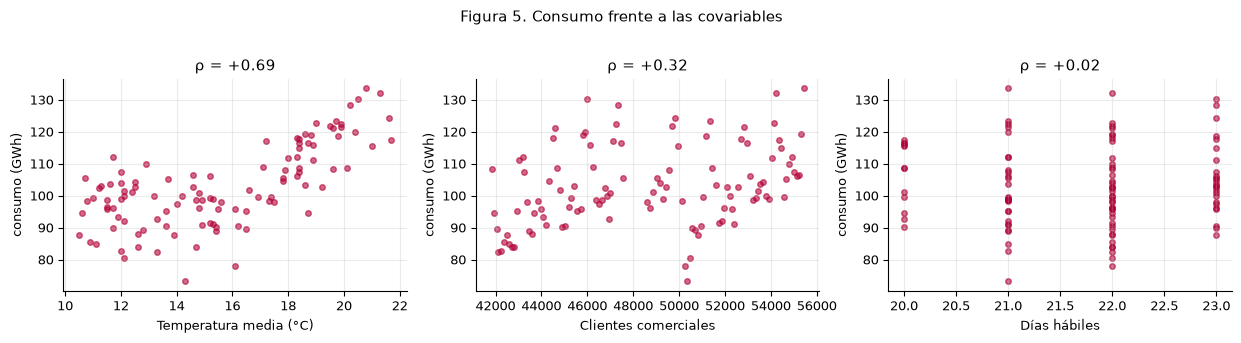

Correlaciones con el consumo: {'temperatura_media_c': 0.686, 'clientes_comerciales': 0.319, 'dias_habiles': 0.016}
Correlación de la razón serie/nivel con temperatura: 0.736 | con días hábiles: 0.033
Clientes comerciales (mar, abr, may 2019): [47561, 48620, 48720]
Consumo medio por temperatura:
temperatura_media_c
(0, 12]      97.1
(12, 14]     95.0
(14, 16]     95.3
(16, 18]    100.1
(18, 25]    116.8


In [9]:
# ============================================================
# 3.5 Relación con las covariables (uso explicativo)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.3))
for ax, var, etq in zip(axes, ["temperatura_media_c", "clientes_comerciales", "dias_habiles"],
                        ["Temperatura media (°C)", "Clientes comerciales", "Días hábiles"]):
    ax.scatter(df[var], y, s=16, alpha=0.6, color=ROJO)
    ax.set_xlabel(etq); ax.set_ylabel("consumo (GWh)")
    ax.set_title(f"ρ = {np.corrcoef(df[var], y)[0, 1]:+.2f}")
plt.suptitle("Figura 5. Consumo frente a las covariables", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

print("Correlaciones con el consumo:",
      {v: round(float(np.corrcoef(df[v], y)[0, 1]), 3) for v in ["temperatura_media_c", "clientes_comerciales", "dias_habiles"]})
# Razón serie/nivel (estacionalidad + irregular) frente a la temperatura y a los días hábiles
rz = (y / y.rolling(12, center=True).mean().rolling(2, center=True).mean().shift(-1)).dropna()
print("Correlación de la razón serie/nivel con temperatura:", round(np.corrcoef(rz, df.loc[rz.index, "temperatura_media_c"])[0, 1], 3),
      "| con días hábiles:", round(np.corrcoef(rz, df.loc[rz.index, "dias_habiles"])[0, 1], 3))
# Clientes: salto puntual de abril de 2019
print("Clientes comerciales (mar, abr, may 2019):",
      df.loc["2019-03-01":"2019-05-01", "clientes_comerciales"].tolist())
print("Consumo medio por temperatura:")
print(y.groupby(pd.cut(df["temperatura_media_c"], [0, 12, 14, 16, 18, 25])).mean().round(1).to_string())

**Descripción (Figura 5).** La temperatura es la variable más relacionada con el consumo (ρ = +0,69), mostrando una relación estacional importante. Los clientes presentan una asociación menor (ρ = +0,32) y su aumento no genera un cambio claro en el consumo. Los días hábiles prácticamente no muestran relación (ρ = +0,02).

**Decisión — enfoque univariado.** Se trabajará solo con consumo_gwh, ya que la temperatura requeriría ser proyectada, los clientes aportan poca información adicional y los días hábiles no muestran una relación relevante.

## 3.6 Delimitación y magnitud del efecto COVID-19

In [10]:
# ============================================================
# 3.6 Delimitación y magnitud del efecto COVID-19 (contrafactual simple)
# ============================================================
# Contrafactual: promedio del mismo mes de 2018 y 2019 (nivel anual estable entre ambos años)
base = pd.concat([y["2018"], y["2019"]]).groupby(lambda f: f.month).mean()
contra = pd.Series(base.reindex(y.index.month).values, index=y.index)
brecha = (y / contra - 1) * 100

ventana = slice("2020-01-01", "2022-12-01")
print("Desviación % respecto del contrafactual (2020-2022):")
print(brecha[ventana].round(1).to_frame("desv. %").T.to_string())

w = slice(COVID_INI, COVID_FIN)
perdida = (contra[w] - y[w]).sum()
print(f"\nEnergía no consumida mar-2020 a dic-2021: {perdida:.1f} GWh "
      f"({100 * perdida / contra[w].sum():.1f}% de lo esperado)")
print(f"Mes de mayor caída: {brecha[w].idxmin():%Y-%m} ({brecha[w].min():.1f}%)")
bajo = brecha[COVID_INI:"2022-12-01"][brecha[COVID_INI:"2022-12-01"] < -3]
print(f"Último mes con desviación < -3%: {bajo.index.max():%Y-%m} -> retorno sostenido desde "
      f"{bajo.index.max() + pd.DateOffset(months=1):%Y-%m}")

Desviación % respecto del contrafactual (2020-2022):
fecha    2020-01-01  2020-02-01  2020-03-01  2020-04-01  2020-05-01  2020-06-01  2020-07-01  2020-08-01  2020-09-01  2020-10-01  2020-11-01  2020-12-01  2021-01-01  2021-02-01  2021-03-01  2021-04-01  2021-05-01  2021-06-01  2021-07-01  2021-08-01  2021-09-01  2021-10-01  2021-11-01  2021-12-01  2022-01-01  2022-02-01  2022-03-01  2022-04-01  2022-05-01  2022-06-01  2022-07-01  2022-08-01  2022-09-01  2022-10-01  2022-11-01  2022-12-01
desv. %        -3.8        -0.4        -8.4       -20.5       -24.4       -19.4       -13.4       -12.5        -8.5       -11.2       -11.5        -2.7        -4.6        -6.3        -3.5        -7.0        -4.9        -3.7        -1.1        -1.9         0.1       -10.4        -8.8        -3.6        -5.9         0.4        -0.8         0.2         2.6         1.5        -0.4         2.4         4.5        -2.6        -0.8         0.5

Energía no consumida mar-2020 a dic-2021: 194.6 GWh (8.4% de lo es

**Descripción.** Para estimar el impacto se utilizó un contrafactual basado en el promedio del mismo mes de 2018 y 2019. Se eligieron esos años porque presentan niveles anuales casi iguales (107,1 y 107,2 GWh), lo que permite realizar una comparación estable sin extrapolar una tendencia que ya se había detenido.
Con este punto de referencia, la primera caída importante aparece en marzo de 2020 (−8,4 %). El descenso más fuerte ocurre en mayo de 2020 (−24,4 %). Después se observa una recuperación gradual hacia fines de 2020, aunque vuelven a registrarse caídas relevantes en octubre y noviembre de 2020, así como en octubre y noviembre de 2021.
Usando como criterio una desviación mayor a -3 %, la normalización sostenida se alcanza en febrero de 2022. Por ello, el periodo afectado se considera desde marzo de 2020 hasta enero de 2022.
En total, entre marzo de 2020 y diciembre de 2021 se dejaron de consumir aproximadamente 194,6 GWh, equivalentes al 8,4 % de la energía esperada.
Esta estimación es conservadora, ya que el contrafactual supone crecimiento nulo, mientras que la tendencia histórica era cercana al 2,8 % anual.


# 4. Descomposición de la serie e identificación de componentes
Se aplica una descomposición clásica por medias móviles (seasonal_decompose, periodo 12) para separar la serie en tendencia, estacionalidad y residuo. La tendencia se obtiene mediante medias móviles y la estacionalidad a partir del comportamiento que se repite cada mes. Se eligió este método por ser simple de interpretar. Sus limitaciones y la alternativa STL (Cleveland et al., 1990) se revisan al final.

### Decisión 3 — Esquema aditivo o multiplicativo
En el esquema aditivo ($y_t = T_t + S_t + R_t$), la estacionalidad mantiene una magnitud similar en GWh. En el multiplicativo ($y_t = T_t \times S_t \times R_t$), la estacionalidad cambia de forma proporcional al nivel de consumo.

## 4.1 Descomposición clásica

In [11]:
# ============================================================
# 4.1 Descomposición clásica: aditiva vs. multiplicativa
# ============================================================
dec_add = seasonal_decompose(y, model="additive", period=12)
dec_mul = seasonal_decompose(y, model="multiplicative", period=12)

# Criterio de elección: un esquema es adecuado si su residuo es homogéneo respecto del nivel.
# Medimos la dispersión del residuo RELATIVA al nivel (tendencia) en el tramo sin COVID.
tramo = [(pd.Timestamp("2015-07-01"), pd.Timestamp("2019-12-01")),
         (pd.Timestamp("2022-01-01"), pd.Timestamp("2023-06-01"))]
def sin_covid(serie):
    return pd.concat([serie[a:b] for a, b in tramo]).dropna()

r_add = sin_covid(dec_add.resid / dec_add.trend * 100)   # % del nivel
r_mul = sin_covid((dec_mul.resid - 1) * 100)             # % (ya es razón)
tabla_esq = pd.DataFrame({
    "aditivo": {"desv. residuo (% del nivel)": r_add.std(),
                "corr(|residuo|, nivel)": np.corrcoef(sin_covid(dec_add.resid).abs(), sin_covid(dec_add.trend))[0, 1]},
    "multiplicativo": {"desv. residuo (% del nivel)": r_mul.std(),
                       "corr(|residuo|, nivel)": np.corrcoef(sin_covid(dec_mul.resid - 1).abs(), sin_covid(dec_mul.trend))[0, 1]},
}).round(3)
display(tabla_esq)

,aditivo,multiplicativo
desv. residuo (% del nivel),2.358,2.456
"corr(|residuo|, nivel)",0.194,0.185


| Elemento | Detalle |
|---|---|
| **Qué se decidió** | Usar el esquema **multiplicativo** para analizar los componentes de la serie. |
| **A favor** | La amplitud relativa se mantiene cerca del 30 % (31,8 % a 30,0 %), mientras la absoluta aumenta de 28,8 a 34,1 GWh. Esto indica que la estacionalidad tiende a variar junto con el nivel de consumo.|
| **En contra** | La elasticidad es solo 0,31 y los residuos son similares en ambos modelos (2,36 % aditivo y 2,46 % multiplicativo). Por esto, el esquema aditivo también podría ser válido.|
| **Alternativa descartada** | Aunque el modelo aditivo es razonable, se prefiere el multiplicativo porque permite interpretar la estacionalidad como porcentaje y es consistente con la amplitud relativa observada. STL se evaluará en la etapa de modelamiento.|
| **Consecuencia** | Los componentes se leen como porcentaje del nivel. En la Semana 2 se verificará la elección comparando log y Box-Cox; la ambigüedad es una limitación reconocida. |

## 4.2 Componentes estimados

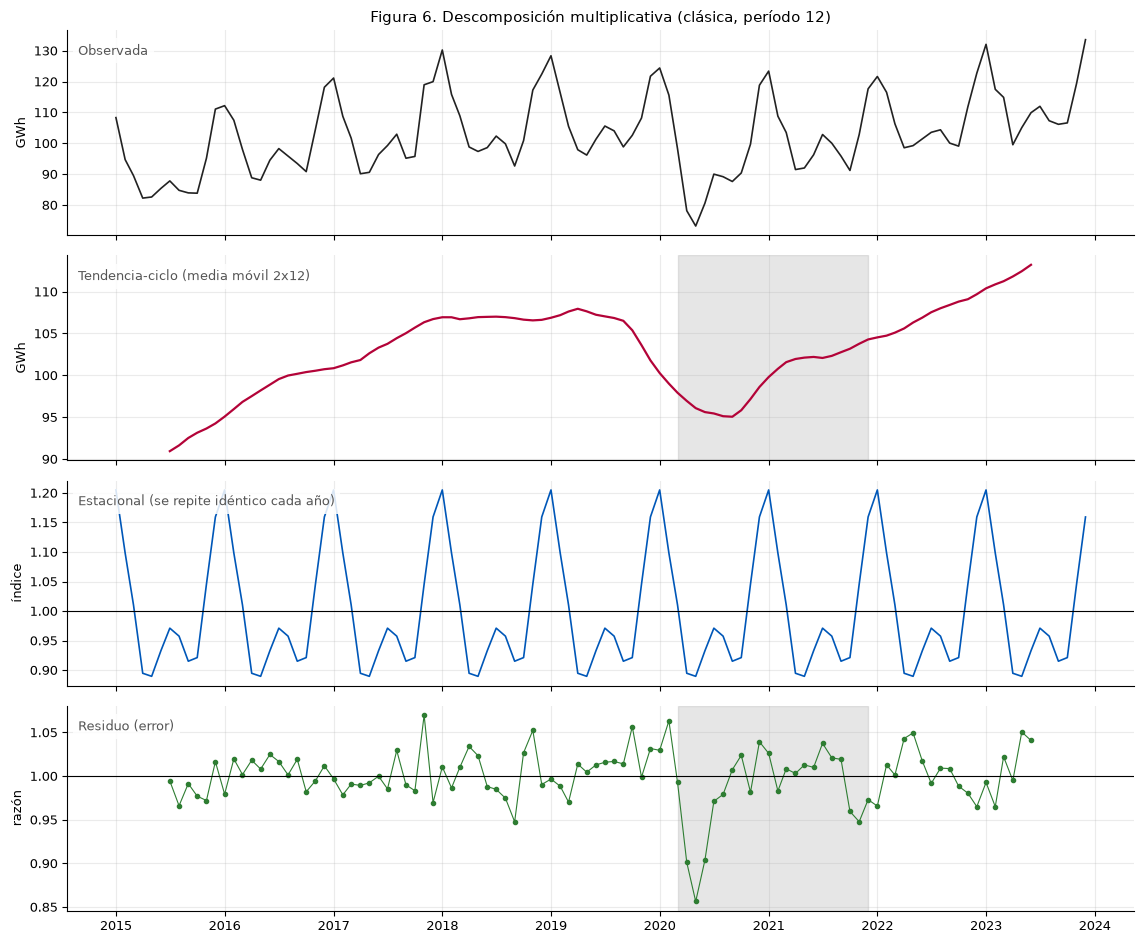

In [12]:
# ============================================================
# 4.2 Componentes del esquema multiplicativo
# ============================================================
fig, axes = plt.subplots(4, 1, figsize=(11.5, 9.5), sharex=True)
axes[0].plot(dec_mul.observed, color=NEGRO, lw=1.2); axes[0].set_ylabel("GWh")
axes[0].set_title("Figura 6. Descomposición multiplicativa (clásica, período 12)")
axes[0].text(0.01, 0.88, "Observada", transform=axes[0].transAxes, fontsize=9, color="#555555", bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
axes[1].plot(dec_mul.trend, color=ROJO, lw=1.6); axes[1].set_ylabel("GWh")
axes[1].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[1].text(0.01, 0.88, "Tendencia-ciclo (media móvil 2x12)", transform=axes[1].transAxes, fontsize=9, color="#555555", bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
axes[2].plot(dec_mul.seasonal, color=AZUL, lw=1.2); axes[2].axhline(1, color="k", lw=0.8)
axes[2].set_ylabel("índice")
axes[2].text(0.01, 0.88, "Estacional (se repite idéntico cada año)", transform=axes[2].transAxes, fontsize=9, color="#555555", bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
axes[3].plot(dec_mul.resid, "o-", color=VERDE, lw=0.8, ms=3); axes[3].axhline(1, color="k", lw=0.8)
axes[3].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25); axes[3].set_ylabel("razón")
axes[3].text(0.01, 0.88, "Residuo (error)", transform=axes[3].transAxes, fontsize=9, color="#555555", bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
plt.tight_layout(); plt.show()

In [13]:
# ============================================================
# 4.3 Cuantificación de componentes
# ============================================================
T, S, R = dec_mul.trend.dropna(), dec_mul.seasonal, dec_mul.resid.dropna()

# Índice estacional (idéntico cada año por construcción)
idx_est = S.groupby(S.index.month).first()
print("Índice estacional mensual:", dict(zip(idx_est.index, idx_est.round(3))))
print(f"Mes máximo: {idx_est.idxmax()} ({idx_est.max():.3f}) · mes mínimo: {idx_est.idxmin()} ({idx_est.min():.3f}) "
      f"· razón máx/mín = {idx_est.max() / idx_est.min():.2f}")

# Fuerza de tendencia y estacionalidad (Hyndman y Athanasopoulos, 2021), sobre logaritmos
# porque el esquema es multiplicativo: log(y) = log(T) + log(S) + log(R)
lT, lS, lR = np.log(T), np.log(S.loc[R.index]), np.log(R)
lT = lT.loc[R.index]
Ft = max(0, 1 - lR.var() / (lT + lR).var())
Fs = max(0, 1 - lR.var() / (lS + lR).var())
print(f"Fuerza de la tendencia     Ft = {Ft:.2f}")
print(f"Fuerza de la estacionalidad Fs = {Fs:.2f}")

# Tendencia: crecimiento por tramos
# (los extremos de la media móvil están contaminados cerca del shock: se eligen tramos prudentes)
for a, b in [("2015-07-01", "2018-01-01"), ("2018-01-01", "2019-06-01"),
             ("2019-06-01", "2020-09-01"), ("2020-09-01", "2022-06-01"), ("2022-06-01", "2023-06-01")]:
    print(f"Tendencia {a[:7]} -> {b[:7]}: {T[a]:.1f} -> {T[b]:.1f} GWh ({100 * (T[b] / T[a] - 1):+.1f}%)")
crec_anual = 100 * ((T["2023-06-01"] / T["2015-07-01"]) ** (12 / ((T.index.get_loc(pd.Timestamp("2023-06-01"))
                                                                    - T.index.get_loc(pd.Timestamp("2015-07-01"))))) - 1)
print(f"Crecimiento medio anual de la tendencia (2015-07 a 2023-06): {crec_anual:.2f}%")

# Ciclo: movimientos de baja frecuencia de la tendencia respecto de su recta de largo plazo
t = np.arange(len(T)); b1, b0 = np.polyfit(t, np.log(T.values), 1)
ciclo = pd.Series(np.log(T.values) - (b0 + b1 * t), index=T.index) * 100
print(f"\nCiclo (desv. % de la tendencia respecto de su recta log-lineal): mín {ciclo.min():.1f}% "
      f"({ciclo.idxmin():%Y-%m}), máx {ciclo.max():.1f}% ({ciclo.idxmax():%Y-%m})")

# Error
print(f"\nResiduo: media {R.mean():.3f}, desv. estándar {R.std():.3f} (≈{100 * R.std():.1f}% del nivel)")
print("Mayores desvíos del residuo (razón):")
print(R.sub(1).abs().sort_values(ascending=False).head(8).round(3).to_string())

Índice estacional mensual: {1: 1.205, 2: 1.098, 3: 1.01, 4: 0.895, 5: 0.89, 6: 0.933, 7: 0.971, 8: 0.958, 9: 0.915, 10: 0.921, 11: 1.046, 12: 1.159}
Mes máximo: 1 (1.205) · mes mínimo: 5 (0.890) · razón máx/mín = 1.35
Fuerza de la tendencia     Ft = 0.75
Fuerza de la estacionalidad Fs = 0.90
Tendencia 2015-07 -> 2018-01: 90.9 -> 106.9 GWh (+17.6%)
Tendencia 2018-01 -> 2019-06: 106.9 -> 107.2 GWh (+0.3%)
Tendencia 2019-06 -> 2020-09: 107.2 -> 95.1 GWh (-11.4%)
Tendencia 2020-09 -> 2022-06: 95.1 -> 106.9 GWh (+12.5%)
Tendencia 2022-06 -> 2023-06: 106.9 -> 113.2 GWh (+5.9%)
Crecimiento medio anual de la tendencia (2015-07 a 2023-06): 2.81%

Ciclo (desv. % de la tendencia respecto de su recta log-lineal): mín -9.3% (2020-09), máx 5.6% (2018-01)

Residuo: media 1.000, desv. estándar 0.033 (≈3.3% del nivel)
Mayores desvíos del residuo (razón):
fecha
2020-05-01    0.144
2020-04-01    0.099
2020-06-01    0.096
2017-11-01    0.070
2020-02-01    0.063
2019-10-01    0.057
2018-09-01    0.052
2018

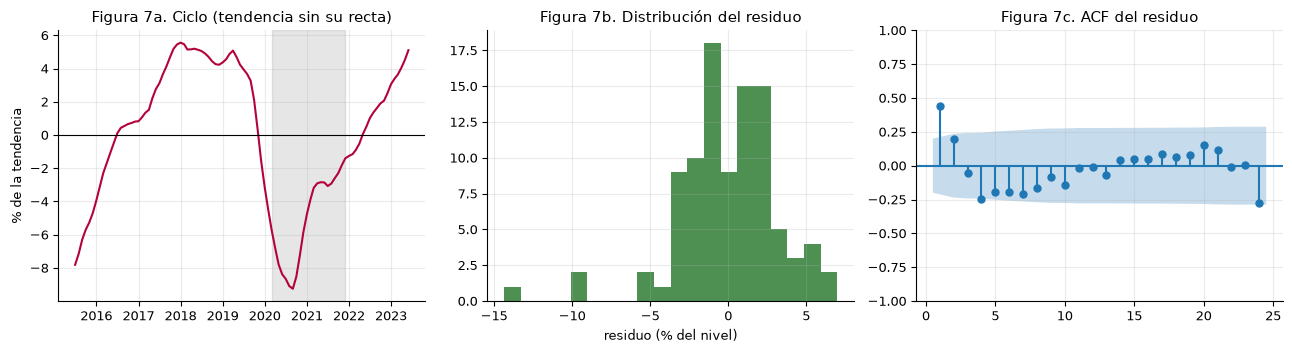

Desv. del residuo: con COVID 0.0325 · sin COVID 0.0254 · solo COVID 0.0472
ACF del residuo: rezago 1 = +0.44, rezago 2 = +0.20, rezago 12 = -0.01 (banda ±0.20)


In [14]:
# ============================================================
# 4.4 Ciclo y error: visualización
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(ciclo, color=ROJO); axes[0].axhline(0, color="k", lw=0.8)
axes[0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0].set_ylabel("% de la tendencia"); axes[0].set_title("Figura 7a. Ciclo (tendencia sin su recta)")
axes[1].hist(R.sub(1) * 100, bins=20, color=VERDE, alpha=0.85)
axes[1].set_xlabel("residuo (% del nivel)"); axes[1].set_title("Figura 7b. Distribución del residuo")
plot_acf(R.values, lags=24, ax=axes[2], zero=False, title="Figura 7c. ACF del residuo")
plt.tight_layout(); plt.show()

# Dispersión del residuo con y sin la ventana COVID
cov = (R.index >= COVID_INI) & (R.index <= COVID_FIN)
print(f"Desv. del residuo: con COVID {R.std():.4f} · sin COVID {R[~cov].std():.4f} · solo COVID {R[cov].std():.4f}")
n_r = len(R); banda_r = 1.96 / np.sqrt(n_r)
ar = acf(R.values, nlags=24)
print(f"ACF del residuo: rezago 1 = {ar[1]:+.2f}, rezago 2 = {ar[2]:+.2f}, rezago 12 = {ar[12]:+.2f} "
      f"(banda ±{banda_r:.2f})")

**Tendencia.** La tendencia-ciclo (Figura 6) aumenta de 90,9 GWh en 2015 a 106,9 GWh en 2018. Luego se mantiene más estable durante 2018-2019 y cae hasta 95,1 GWh en 2020. Después se recupera y llega a 113,2 GWh en 2023. En todo el periodo, el crecimiento promedio anual es de 2,8 %.

**Estacionalidad.** La serie presenta una estacionalidad anual de 12 meses, con valores entre 0,890 en mayo y 1,205 en enero. La fuerza de la estacionalidad es Fs = 0,90, superior al Ft = 0,75 de la tendencia (Hyndman y Athanasopoulos, 2021). Esto muestra que la estacionalidad es el componente que más influye en la serie.

**Ciclo.** En los 9 años analizados no se observa un ciclo que se repita de forma clara. Los principales cambios son el estancamiento de 2018-2019 y la caída de 2020, que alcanza -9,3 % en septiembre (Figura 7a). Esta caída se relaciona con un shock externo, por lo que la serie se puede resumir como tendencia + estacionalidad + intervención, sin un ciclo claramente identificable.

**Error.** El residuo presenta una desviación de 3,3 % del nivel, que baja a 2,5 % sin el periodo COVID y aumenta a 4,7 % durante este periodo. Los mayores desvíos aparecen en abril, mayo y junio de 2020 (−9,9 %, −14,4 % y −9,6 %) y en noviembre de 2017 (+7,0 %). Además, los residuos no son ruido blanco, ya que presentan autocorrelación (ρ₁ = +0,44 y ρ₂ = +0,20).


**Lectura de las Figuras 7a-7c.** El ciclo muestra el estancamiento previo al COVID y la caída posterior. Los residuos se concentran cerca de 0, pero presentan valores negativos durante el COVID. Su autocorrelación indica que la descomposición no captura completamente este efecto, ya que dura varios meses y no puede ser representado por una estacionalidad fija ni por una media móvil suave.

**Limitaciones.** La descomposición clásica usa una media móvil, por lo que puede suavizar cambios bruscos y perder datos en los extremos. STL es una alternativa más flexible para la etapa de modelamiento.


# 5. Análisis de autocorrelación (ACF y PACF)

La **ACF** mide la relación de la serie con sus valores anteriores, mientras que la PACF mide esa relación descontando el efecto de los rezagos intermedios (Box et al., 2015). Se analizan hasta 48 rezagos porque la serie es mensual y tiene una estacionalidad de 12 meses, por lo que 48 meses permiten observar hasta cuatro ciclos anuales. Con n = 108 observaciones, la banda aproximada de significancia al 95 % se calcula como ±1,96/√108 = ±0,189. Por lo tanto, las barras que superan aproximadamente ±0,19 indican una autocorrelación significativa. Los gráficos de statsmodels pueden mostrar bandas algo diferentes porque utilizan el ajuste de Bartlett.

## 5.1 Correlogramas de la serie

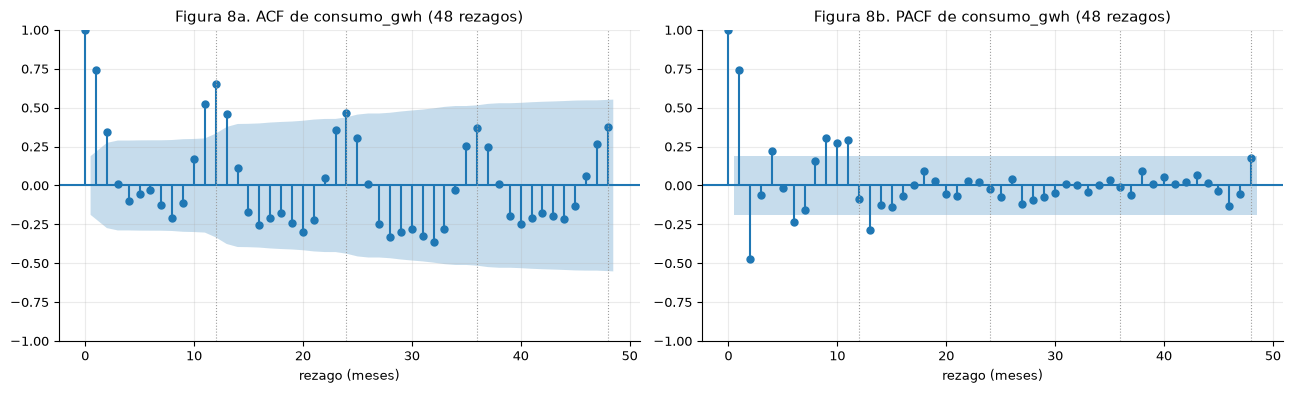

In [15]:
# ============================================================
# 5.1 ACF y PACF de la serie (nivel), 48 rezagos
# ============================================================
NLAGS = 48
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(y.values, lags=NLAGS, ax=axes[0], title="Figura 8a. ACF de consumo_gwh (48 rezagos)")
plot_pacf(y.values, lags=NLAGS, ax=axes[1], method="ywm", title="Figura 8b. PACF de consumo_gwh (48 rezagos)")
for ax in axes:
    ax.set_xlabel("rezago (meses)")
    for k in (12, 24, 36, 48):
        ax.axvline(k, color=GRIS, ls=":", lw=0.8)
plt.tight_layout(); plt.show()

In [16]:
# ============================================================
# 5.2 Valores y rezagos significativos (banda ±1,96/√n)
# ============================================================
n = len(y); banda = 1.96 / np.sqrt(n)
r = acf(y.values, nlags=NLAGS)
p = pacf(y.values, nlags=NLAGS, method="ywm")

clave = [1, 2, 3, 6, 9, 12, 13, 18, 24, 36, 48]
tabla = pd.DataFrame({"ACF": r[clave], "PACF": p[clave]}, index=pd.Index(clave, name="rezago")).round(3)
tabla["ACF signif."] = np.abs(r[clave]) > banda
tabla["PACF signif."] = np.abs(p[clave]) > banda
display(tabla)

print(f"n = {n}; banda de confianza 95% = ±{banda:.3f}")
print("Rezagos ACF significativos :", [k for k in range(1, NLAGS + 1) if abs(r[k]) > banda])
print("Rezagos PACF significativos:", [k for k in range(1, NLAGS + 1) if abs(p[k]) > banda])
print("ACF en múltiplos de 12     :", {k: round(float(r[k]), 3) for k in (12, 24, 36, 48)})

,ACF,PACF,ACF signif.,PACF signif.
rezago,,,,
1,0.745,0.745,True,True
2,0.345,-0.469,True,True
3,0.007,-0.061,False,False
6,-0.032,-0.235,False,True
9,-0.115,0.307,False,True
12,0.652,-0.087,True,False
13,0.459,-0.283,True,True
18,-0.179,0.095,False,False
24,0.468,-0.022,True,False


n = 108; banda de confianza 95% = ±0.189
Rezagos ACF significativos : [1, 2, 8, 11, 12, 13, 16, 17, 19, 20, 21, 23, 24, 25, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 39, 40, 41, 43, 44, 47, 48]
Rezagos PACF significativos: [1, 2, 4, 6, 9, 10, 11, 13]
ACF en múltiplos de 12     : {12: 0.652, 24: 0.468, 36: 0.369, 48: 0.378}


## 5.2 Interpretación

**Persistencia.** La **ACF** comienza con valores altos en los primeros rezagos (ρ₁ = 0,745 y ρ₂ = 0,345) y baja casi a cero en el rezago 3 (ρ₃ = 0,007). En la serie desestacionalizada, ρ₁ aumenta a 0,87 (Figura 9a), mostrando una fuerte persistencia del nivel. Esto, junto con los cambios en la media, indica que la serie no es estacionaria.

**Estacionalidad.** La ACF presenta valores significativos en los rezagos 12, 24, 36 y 48 (0,652; 0,468; 0,369 y 0,378). Estos picos cada 12 meses confirman una estacionalidad anual que se mantiene en el tiempo. Además, su disminución lenta es otra señal de que la serie no es estacionaria.

**Dependencia directa (PACF).** La PACF muestra valores importantes en los primeros rezagos (0,745 y -0,469) y otros significativos en los rezagos 4, 6, 9, 10, 11 y 13 (este último, vecino del rezago estacional: −0,283), pero no presenta un pico claro en los rezagos estacionales 12, 24 y 36. Esto podría indicar una dependencia de corto plazo, aunque su interpretación es provisoria mientras la serie no sea estacionaria.

**Límite.** El correlograma permite identificar señales de no estacionariedad y estacionalidad anual, pero todavía no permite definir de forma confiable los órdenes (p,q)(P,Q). Estos se evaluarán después de estacionarizar la serie.

## 5.3 Contraste: serie desestacionalizada y residuo

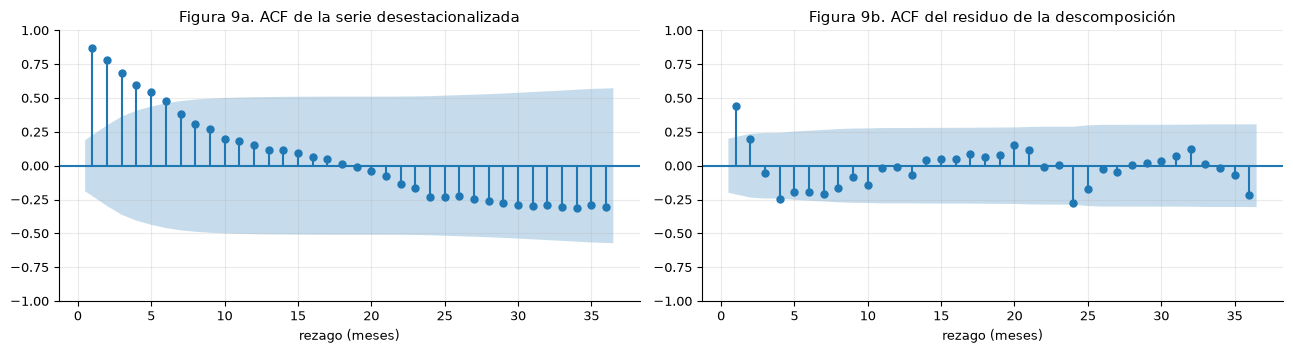

ACF desestacionalizada: rezago 1 = 0.87 | rezago 12 = 0.15 | rezago 24 = -0.23
ACF del residuo       : rezago 1 = 0.44 | rezago 12 = -0.01 | rezago 24 = -0.27


In [17]:
# ============================================================
# 5.3 Contraste: ¿qué ocurre con la ACF al retirar tendencia y estacionalidad?
# ============================================================
# Serie desestacionalizada (y / índice estacional) y residuo de la descomposición
y_dsz = (y / dec_mul.seasonal).dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(y_dsz.values, lags=36, ax=axes[0], zero=False, title="Figura 9a. ACF de la serie desestacionalizada")
plot_acf(R.values, lags=36, ax=axes[1], zero=False, title="Figura 9b. ACF del residuo de la descomposición")
for ax in axes: ax.set_xlabel("rezago (meses)")
plt.tight_layout(); plt.show()

rd = acf(y_dsz.values, nlags=36)
print("ACF desestacionalizada: rezago 1 =", round(rd[1], 2), "| rezago 12 =", round(rd[12], 2), "| rezago 24 =", round(rd[24], 2))
ra = acf(R.values, nlags=36)
print("ACF del residuo       : rezago 1 =", round(ra[1], 2), "| rezago 12 =", round(ra[12], 2), "| rezago 24 =", round(ra[24], 2))

**Lectura de las Figuras 9a y 9b.** Al dividir por el índice estacional, desaparecen los picos de los rezagos 12, 24 y 36 (ρ₁₂ = 0,15 y ρ₂₄ = -0,23), mostrando que provenían del patrón estacional. Sin embargo, la autocorrelación sigue siendo alta en el primer rezago (ρ₁ = 0,87), debido a la tendencia y al COVID. En los residuos, ρ₁ baja a +0,44 y ρ₁₂ a -0,01, indicando que la estacionalidad fue capturada, aunque aún queda dependencia de corto plazo.

# 6. Interpretación técnica integrada

## 6.1 Convergencia de la evidencia

| Componente | Gráficos exploratorios | Descomposición | ACF / PACF |
|---|---|---|---|
| **Tendencia** | La serie crece entre 2015 y 2018, se estabiliza en 2018-2019, cae en 2020 y luego se recupera (Figuras 1 y 4a).|La tendencia aumenta de 90,9 a 113,2 GWh, con un crecimiento promedio de 2,8 % anual (Ft = 0,75). | La autocorrelación disminuye lentamente y la serie desestacionalizada presenta ρ₁ = 0,87, lo que indica que la media no es constante. |
| **Estacionalidad** | El consumo alcanza su máximo en enero (1,19) y su mínimo en mayo (0,89), con un repunte en invierno (Figuras 3a-3c).| El índice estacional varía entre 0,890 y 1,205 y presenta una fuerza de Fs = 0,90, superior a la tendencia.|Se observan picos en los rezagos 12, 24, 36 y 48 (0,65; 0,47; 0,37; 0,38), confirmando una estacionalidad anual marcada.|
| **Ciclo** | Solo se observa el estancamiento de 2018-2019 y la caída de 2020.|El componente fluctúa entre +5,6 % y -9,3 %, sin mostrar una periodicidad clara.| No se observan patrones distintos de la estacionalidad anual.|
| **Shocks** | Destacan la caída iniciada en marzo de 2020 (mínimo de -24,4 % y 194,6 GWh perdidos) y el atípico de noviembre de 2017.|Los residuos más extremos se concentran en 2020 y en noviembre de 2017.|El residuo mantiene autocorrelación (ρ₁ = +0,44), lo que indica que aún queda estructura sin explicar.|
| **Error** | La desviación estándar móvil se mantiene entre 8 y 13 GWh fuera del COVID (Figura 4a) |La desviación del residuo es de 3,3 % del nivel (2,5 % sin COVID).|El patrón estacional desaparece en los residuos (ρ₁₂ = -0,01).|

## 6.2 Conclusión técnica

La serie es **no estacionaria en media** y presenta una estacionalidad anual fuerte y estable, una tendencia creciente con estancamiento en 2018-2019, el impacto del COVID y un atípico confirmado en noviembre de 2017. Esta conclusión está respaldada por los gráficos exploratorios, la descomposición (Fs = 0,90 y Ft = 0,75) y la ACF, que muestra picos en múltiplos de 12 meses y una autocorrelación de ρ₁ = 0,87 en la serie desestacionalizada. La estacionalidad se explica principalmente por el verano y, en menor medida, por el invierno.

## 6.3 Implicancias para el modelamiento
1. **Transformación.** Comparar la serie original, el logaritmo y Box-Cox para seleccionar la transformación más adecuada en la Semana 2.
2. **Diferenciación.** La ACF sugiere aplicar una diferencia regular (d = 1) y una estacional (D = 1). Esta decisión se confirmará con las pruebas ADF y KPSS. La diferencia estacional se realizará con serie.diff(12).
3. **Quiebre COVID.** El shock de 2020 puede afectar la diferenciación y el modelamiento. Se evaluará si conviene incorporarlo mediante variables indicadoras o ajustar la muestra de análisis.
4. **Atípico de 2017.** El dato de noviembre de 2017 se tratará como un valor faltante o mediante una variable indicadora.
5. **Covariables.** Se mantendrá un enfoque univariado (SARIMA). La temperatura podría incorporarse más adelante en un modelo SARIMAX.
6. **Referencia.** Dado que la estacionalidad es el componente dominante (Fs = 0,90), el modelo deberá superar el desempeño del pronóstico ingenuo estacional.

## 6.4 Limitaciones
Los 9 años de datos, incluidos 2 años afectados por el COVID, limitan la identificación de ciclos y la estimación de la estacionalidad. La descomposición clásica asume una estacionalidad fija y no separa completamente la tendencia del shock. Además, la elección entre un esquema aditivo o multiplicativo no es concluyente. Como los datos son sintéticos, las explicaciones sobre las causas del consumo deben considerarse hipótesis.

# 7. Conclusiones

1. La serie combina tendencia, estacionalidad anual, el impacto del COVID y un atípico en 2017. No se identifican ciclos de largo plazo.

2. La estacionalidad es el componente dominante (Fs = 0,90), con máximo en enero y mínimo en mayo.

3. La tendencia crece cerca de 2,8 % anual, se estanca en 2018-2019 y cae en 2020. El COVID implicó cerca de 195 GWh de consumo no realizado.

4. La ACF muestra picos en 12, 24, 36 y 48 meses, confirmando una serie no estacionaria y estacional. La PACF sugiere dependencia de corto plazo.

5. Para el modelamiento se utilizará inicialmente una transformación logarítmica, diferenciación estacional y el tratamiento explícito del COVID y del atípico de 2017.

# 8. Referencias

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Cleveland, R. B., Cleveland, W. S., McRae, J. E., y Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics, 6*(1), 3–73.

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Seabold, S., y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.

# 9. Declaración de uso de herramientas de IA
Se utilizó un asistente de IA generativa (Claude Anthropic, en Claude Code) para apoyar la elaboración inicial del código, organizar ideas y no para reproducir respuestas completas. El análisis, la interpretación y validación de resultados, más la redacción del informe fueron realizados por el autor.
Asimismo, se revisó el notebook completo, verificando su correcta ejecución de principio a fin y validando el contenido, los resultados y las decisiones metodológicas presentadas en el informe. Finalmente, se revisó según la rúbrica de cumplimiento de Canvas.